# Gatekeeper · 05 — The champion's final test

LightGBM won the model contest on `valid`. Because early stopping also used `valid`, that score is
slightly favourable. This notebook gives the champion its honest test on **`replay`**: the last month
of payments, which no model has seen or been tuned on.

It also:
- loads the model exactly as the scoring API will (saved model file + `preprocess.json`), proving the saved files work;
- fixes the **decision threshold** (the score above which a payment is flagged) using `valid` only;
- packages everything the API needs.

**Inputs:** the output of `01_explore_and_split` (parquet splits) and `04_boosting` (model files).

In [2]:
import os, glob, json, time, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve

SEARCH_ROOT = os.environ.get("GK_DATA_ROOT", "/kaggle/input")
OUT_DIR = os.environ.get("GK_OUT_DIR", "/kaggle/working")
os.makedirs(OUT_DIR, exist_ok=True)

def find(name, source):
    hits = glob.glob(f"{SEARCH_ROOT}/**/{name}", recursive=True)
    if not hits:
        raise FileNotFoundError(f"{name} not found: attach the output of {source} as input")
    return hits[0]

valid = pd.read_parquet(find("valid.parquet", "01_explore_and_split"))
replay = pd.read_parquet(find("replay.parquet", "01_explore_and_split"))
model_path = find("lightgbm_model.txt", "04_boosting")
prep_path = find("preprocess.json", "04_boosting")
print(f"valid {len(valid):,} rows · replay {len(replay):,} rows")

valid 90,568 rows · replay 85,430 rows


## 1. Load the model the way the API will

`prepare()` below is the exact input preparation the API uses: same column order, same text codes,
same missing-value markers. If it matches the training notebook, the live system sees payments
exactly as the model did in training.

In [3]:
booster = lgb.Booster(model_file=model_path)
with open(prep_path) as f:
    prep = json.load(f)
FEATURES, TEXT_COLS, CODES = prep["features"], set(prep["text_cols"]), prep["codes"]

NUM_COLS = [c for c in FEATURES if c not in TEXT_COLS]
NUM_IDX = [FEATURES.index(c) for c in NUM_COLS]
TEXT_IDX = {c: FEATURES.index(c) for c in TEXT_COLS}

def prepare(df):
    # Raw payments -> the model's input matrix, using the same rules as training.
    # Works column-block-wise, so one payment takes ~2 ms even with 431 columns.
    X = df.reindex(columns=FEATURES)
    out = np.empty((len(df), len(FEATURES)), dtype="float32")
    num = X[NUM_COLS].to_numpy(dtype="float32", na_value=np.nan)
    out[:, NUM_IDX] = np.where(np.isnan(num), prep["missing_value"], num)
    miss, unseen = prep["missing_text"], prep["unseen_text"]
    for c, j in TEXT_IDX.items():
        codes = CODES[c]
        out[:, j] = [miss if (v is None or v != v) else codes.get(v, unseen) for v in X[c].tolist()]
    return out

print(f"Model: {booster.num_trees()} trees · {len(FEATURES)} features ({len(TEXT_COLS)} text)")

Model: 472 trees · 431 features (31 text)


## 2. Choose the decision threshold on `valid`

The model outputs a fraud score between 0 and 1. A threshold turns that into **allow** or **suspicious**.
It is chosen on `valid`, never on `replay`, so the final test stays fair.

Two candidate policies:
- **1% false alarms:** flag the riskiest payments while wrongly flagging at most 1 in 100 genuine customers.
- **Lowest cost:** the threshold that minimises money lost, with each wrongly flagged customer costing $10.

In [4]:
FALSE_ALARM_COST = 10.0

def outcome(y, p, amount, threshold):
    flagged = p >= threshold
    caught = (y == 1) & flagged
    false_alarms = (y == 0) & flagged
    missed_usd = amount[(y == 1) & ~flagged].sum()
    return {
        "threshold": round(float(threshold), 4),
        "payments": int(len(y)),
        "flagged": int(flagged.sum()),
        "fraud_total": int(y.sum()),
        "fraud_caught": int(caught.sum()),
        "recall": round(caught.sum() / max(y.sum(), 1), 4),
        "false_alarms": int(false_alarms.sum()),
        "false_alarm_rate": round(false_alarms.sum() / max((y == 0).sum(), 1), 4),
        "precision": round(caught.sum() / max(flagged.sum(), 1), 4),
        "missed_fraud_usd": round(float(missed_usd)),
        "cost_usd": round(float(missed_usd + false_alarms.sum() * FALSE_ALARM_COST)),
        "never_flag_cost_usd": round(float(amount[y == 1].sum())),
    }

yv, av = valid["isFraud"].values, valid["TransactionAmt"].values
pv = booster.predict(prepare(valid))

fpr, tpr, thr = roc_curve(yv, pv)
i = max(np.searchsorted(fpr, 0.01, side="right") - 1, 0)
t_fpr1 = float(thr[i])

grid = np.unique(np.quantile(pv, np.linspace(0.80, 0.9995, 400)))
costs = [outcome(yv, pv, av, t)["cost_usd"] for t in grid]
t_cost = float(grid[int(np.argmin(costs))])

policies = pd.DataFrame([dict(policy="1% false alarms", **outcome(yv, pv, av, t_fpr1)),
                         dict(policy="lowest cost", **outcome(yv, pv, av, t_cost))])
policies[["policy", "threshold", "recall", "false_alarm_rate", "precision", "cost_usd"]]

,policy,threshold,recall,false_alarm_rate,precision,cost_usd
0,1% false alarms,0.1623,0.5279,0.0100,0.6498,256208
1,lowest cost,0.0337,0.7647,0.0663,0.2879,166160


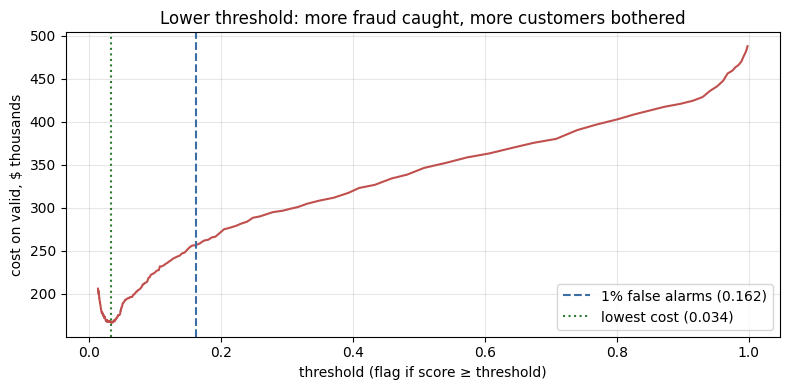

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(grid, np.array(costs) / 1000, color="#c0504d")
ax.axvline(t_fpr1, color="#3b6ea5", ls="--", label=f"1% false alarms ({t_fpr1:.3f})")
ax.axvline(t_cost, color="#2e7d32", ls=":", label=f"lowest cost ({t_cost:.3f})")
ax.set_xlabel("threshold (flag if score ≥ threshold)"); ax.set_ylabel("cost on valid, $ thousands")
ax.set_title("Lower threshold: more fraud caught, more customers bothered")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

The **1% false alarms** policy is used: it matches how every model in the contest was compared, and it
keeps customer friction predictable. The lowest-cost threshold is saved alongside it as an option.

In [6]:
THRESHOLD = t_fpr1
print(f"Chosen threshold: {THRESHOLD:.4f}  (flag a payment if its fraud score ≥ {THRESHOLD:.4f})")

Chosen threshold: 0.1623  (flag a payment if its fraud score ≥ 0.1623)


## 3. The final test: `replay`

The threshold is now fixed. The champion judges the last month of payments, which played no part in
training, tuning, early stopping or choosing the threshold.

In [7]:
yr, ar = replay["isFraud"].values, replay["TransactionAmt"].values
pr = booster.predict(prepare(replay))

final = outcome(yr, pr, ar, THRESHOLD)
final["pr_auc"] = round(average_precision_score(yr, pr), 4)
final["roc_auc"] = round(roc_auc_score(yr, pr), 4)
valid_res = outcome(yv, pv, av, THRESHOLD)
valid_res["pr_auc"] = round(average_precision_score(yv, pv), 4)

compare = pd.DataFrame({"valid (days 121–152)": valid_res, "replay (days 153–182)": final}).loc[
    ["pr_auc", "recall", "false_alarm_rate", "precision", "cost_usd", "never_flag_cost_usd"]]
compare

,valid (days 121–152),replay (days 153–182)
pr_auc,0.6195,0.5515
recall,0.5279,0.4886
false_alarm_rate,0.0100,0.0132
precision,0.6498,0.5728
cost_usd,256208.0000,274475.0000
never_flag_cost_usd,492574.0000,457436.0000


In [8]:
saved = final["never_flag_cost_usd"] - final["cost_usd"]
print(f"Replay month: {final['payments']:,} payments, {final['fraud_total']:,} of them fraud")
print(f"Flagged as suspicious: {final['flagged']:,}")
print(f"  frauds caught:         {final['fraud_caught']:,} of {final['fraud_total']:,} ({final['recall']:.1%})")
print(f"  genuine wrongly flagged: {final['false_alarms']:,} ({final['false_alarm_rate']:.2%} of genuine payments)")
print(f"  share of flags that are fraud: {final['precision']:.1%}")
print(f"Money lost: ${final['cost_usd']:,} vs ${final['never_flag_cost_usd']:,} with no system "
      f"→ ${saved:,} saved ({saved / final['never_flag_cost_usd']:.0%})")

Replay month: 85,430 payments, 2,994 of them fraud
Flagged as suspicious: 2,554
  frauds caught:         1,463 of 2,994 (48.9%)
  genuine wrongly flagged: 1,091 (1.32% of genuine payments)
  share of flags that are fraud: 57.3%
Money lost: $274,475 vs $457,436 with no system → $182,961 saved (40%)


## 4. Speed of one live decision

The API's path for one payment: prepare its inputs, then ask the model. Timed on a single thread,
as the live service runs it.

In [9]:
one = replay.iloc[[0]]
for _ in range(5):
    booster.predict(prepare(one), num_threads=1)
times = []
for k in range(200):
    row = replay.iloc[[k]]
    t0 = time.perf_counter()
    booster.predict(prepare(row), num_threads=1)
    times.append((time.perf_counter() - t0) * 1000)
times = np.array(times)
print(f"One payment, prepare + predict: median {np.median(times):.1f} ms · p99 {np.percentile(times, 99):.1f} ms "
      f"(target: under 50 ms)")

One payment, prepare + predict: median 2.5 ms · p99 4.2 ms (target: under 50 ms)


## 5. Package the champion for the API

Three files go to the scoring API:
- `lightgbm_model.txt`: the trained model
- `preprocess.json`: how to prepare a payment's inputs
- `champion.json`: the threshold, the policy, and the scores behind them

In [10]:
champion = {
    "model": "LightGBM",
    "model_file": "lightgbm_model.txt",
    "trees": booster.num_trees(),
    "features": len(FEATURES),
    "threshold": round(THRESHOLD, 6),
    "threshold_policy": "1% false alarms on valid",
    "threshold_lowest_cost": round(t_cost, 6),
    "false_alarm_cost_usd": FALSE_ALARM_COST,
    "valid": valid_res,
    "replay": final,
    "latency_ms": {"median": round(float(np.median(times)), 2), "p99": round(float(np.percentile(times, 99)), 2)},
}
with open(f"{OUT_DIR}/champion.json", "w") as f:
    json.dump(champion, f, indent=2)
shutil.copy(model_path, f"{OUT_DIR}/lightgbm_model.txt")
shutil.copy(prep_path, f"{OUT_DIR}/preprocess.json")
for name in ["lightgbm_model.txt", "preprocess.json", "champion.json"]:
    print(f"saved {name:<20} {os.path.getsize(f'{OUT_DIR}/{name}') / 1e6:.2f} MB")

saved lightgbm_model.txt   6.57 MB
saved preprocess.json      0.05 MB
saved champion.json        0.00 MB
